# Tadawul Sector Risk Study: walkthrough
Independent study by Amir Khan. Reads the cached public data (`data/raw/prices_adjclose.csv`, Yahoo Finance) and reproduces the key tables and figures. Run `python run.py` first, or `python run.py --refresh` to download the data again.

In [1]:
import sys, json; sys.path.insert(0, '../src')
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from tadawul_risk import config as C, data, stats, vol, risk, corr
pd.set_option('display.precision', 3)
px = data.download()
daily = data.build_panel(px)
print(daily.index.min().date(), daily.index.max().date(), daily.shape)

2015-01-04 2026-10-29 (2978, 7)


## 1. Return statistics

In [2]:
stats.summary(daily)

,start,n_obs,ann_return_%,ann_vol_%,sharpe_rf0,skew,excess_kurt,jb_pvalue,worst_day_%,best_day_%
Banks,2015-01-04,2978,10.09,19.657,0.489,-0.432,6.713,0.0,-9.394,8.106
Materials,2015-01-04,2978,5.207,21.663,0.234,-0.253,5.01,0.0,-9.365,9.447
Energy,2015-01-04,2978,7.27,22.556,0.311,-0.643,5.787,0.0,-8.661,8.63
Telecom,2015-01-04,2978,6.098,20.081,0.295,-0.307,6.591,0.0,-8.369,9.011
Food & Staples,2015-01-04,2978,1.311,23.362,0.056,0.172,4.667,0.0,-8.632,9.939
Utilities,2015-01-04,2978,7.031,26.018,0.261,0.03,5.05,0.0,-10.039,9.925
LargeCap EW,2015-01-04,2978,7.718,16.818,0.442,-0.795,9.023,0.0,-7.951,8.498


## 2. GARCH(1,1) vs GJR-GARCH(1,1), Student-t

In [3]:
gt, cv = vol.garch_table(daily)
gt.set_index(['series','model'])[['alpha','gamma','beta','nu','gamma_pvalue','persistence','aic']]

alpha  gamma   beta     nu  gamma_pvalue  \
series         model                                                  
Banks          GARCH(1,1)  0.129  0.000  0.808  4.165           NaN   
               GJR-GARCH   0.043  0.127  0.837  4.309     2.044e-06   
Materials      GARCH(1,1)  0.105  0.000  0.856  4.576           NaN   
               GJR-GARCH   0.048  0.094  0.870  4.681     1.858e-04   
Energy         GARCH(1,1)  0.156  0.000  0.821  4.467           NaN   
               GJR-GARCH   0.102  0.095  0.824  4.539     3.003e-03   
Telecom        GARCH(1,1)  0.150  0.000  0.764  3.698           NaN   
               GJR-GARCH   0.110  0.078  0.760  3.704     6.089e-02   
Food & Staples GARCH(1,1)  0.135  0.000  0.785  4.202           NaN   
               GJR-GARCH   0.076  0.102  0.811  4.188     1.040e-03   
Utilities      GARCH(1,1)  0.398  0.000  0.504  3.036           NaN   
               GJR-GARCH   0.322  0.151  0.515  3.034     6.938e-02   
LargeCap EW    GARCH(1,1)  0.127  0.000  0.821  4.802           NaN   
               GJR-GARCH   0.022  0.145  0.853  5.052     7.056e-07   

                           persistence        aic  
series         model                               
Banks          GARCH(1,1)        0.938   8992.126  
               GJR-GARCH         0.943   8966.671  
Materials      GARCH(1,1)        0.961   9617.912  
               GJR-GARCH         0.965   9597.332  
Energy         GARCH(1,1)        0.977   9631.536  
               GJR-GARCH         0.973   9620.248  
Telecom        GARCH(1,1)        0.914   9022.956  
               GJR-GARCH         0.910   9019.308  
Food & Staples GARCH(1,1)        0.920  10090.716  
               GJR-GARCH         0.938  10080.318  
Utilities      GARCH(1,1)        0.902  10543.989  
               GJR-GARCH         0.912  10542.308  
LargeCap EW    GARCH(1,1)        0.948   7869.809  
               GJR-GARCH         0.948   7822.340

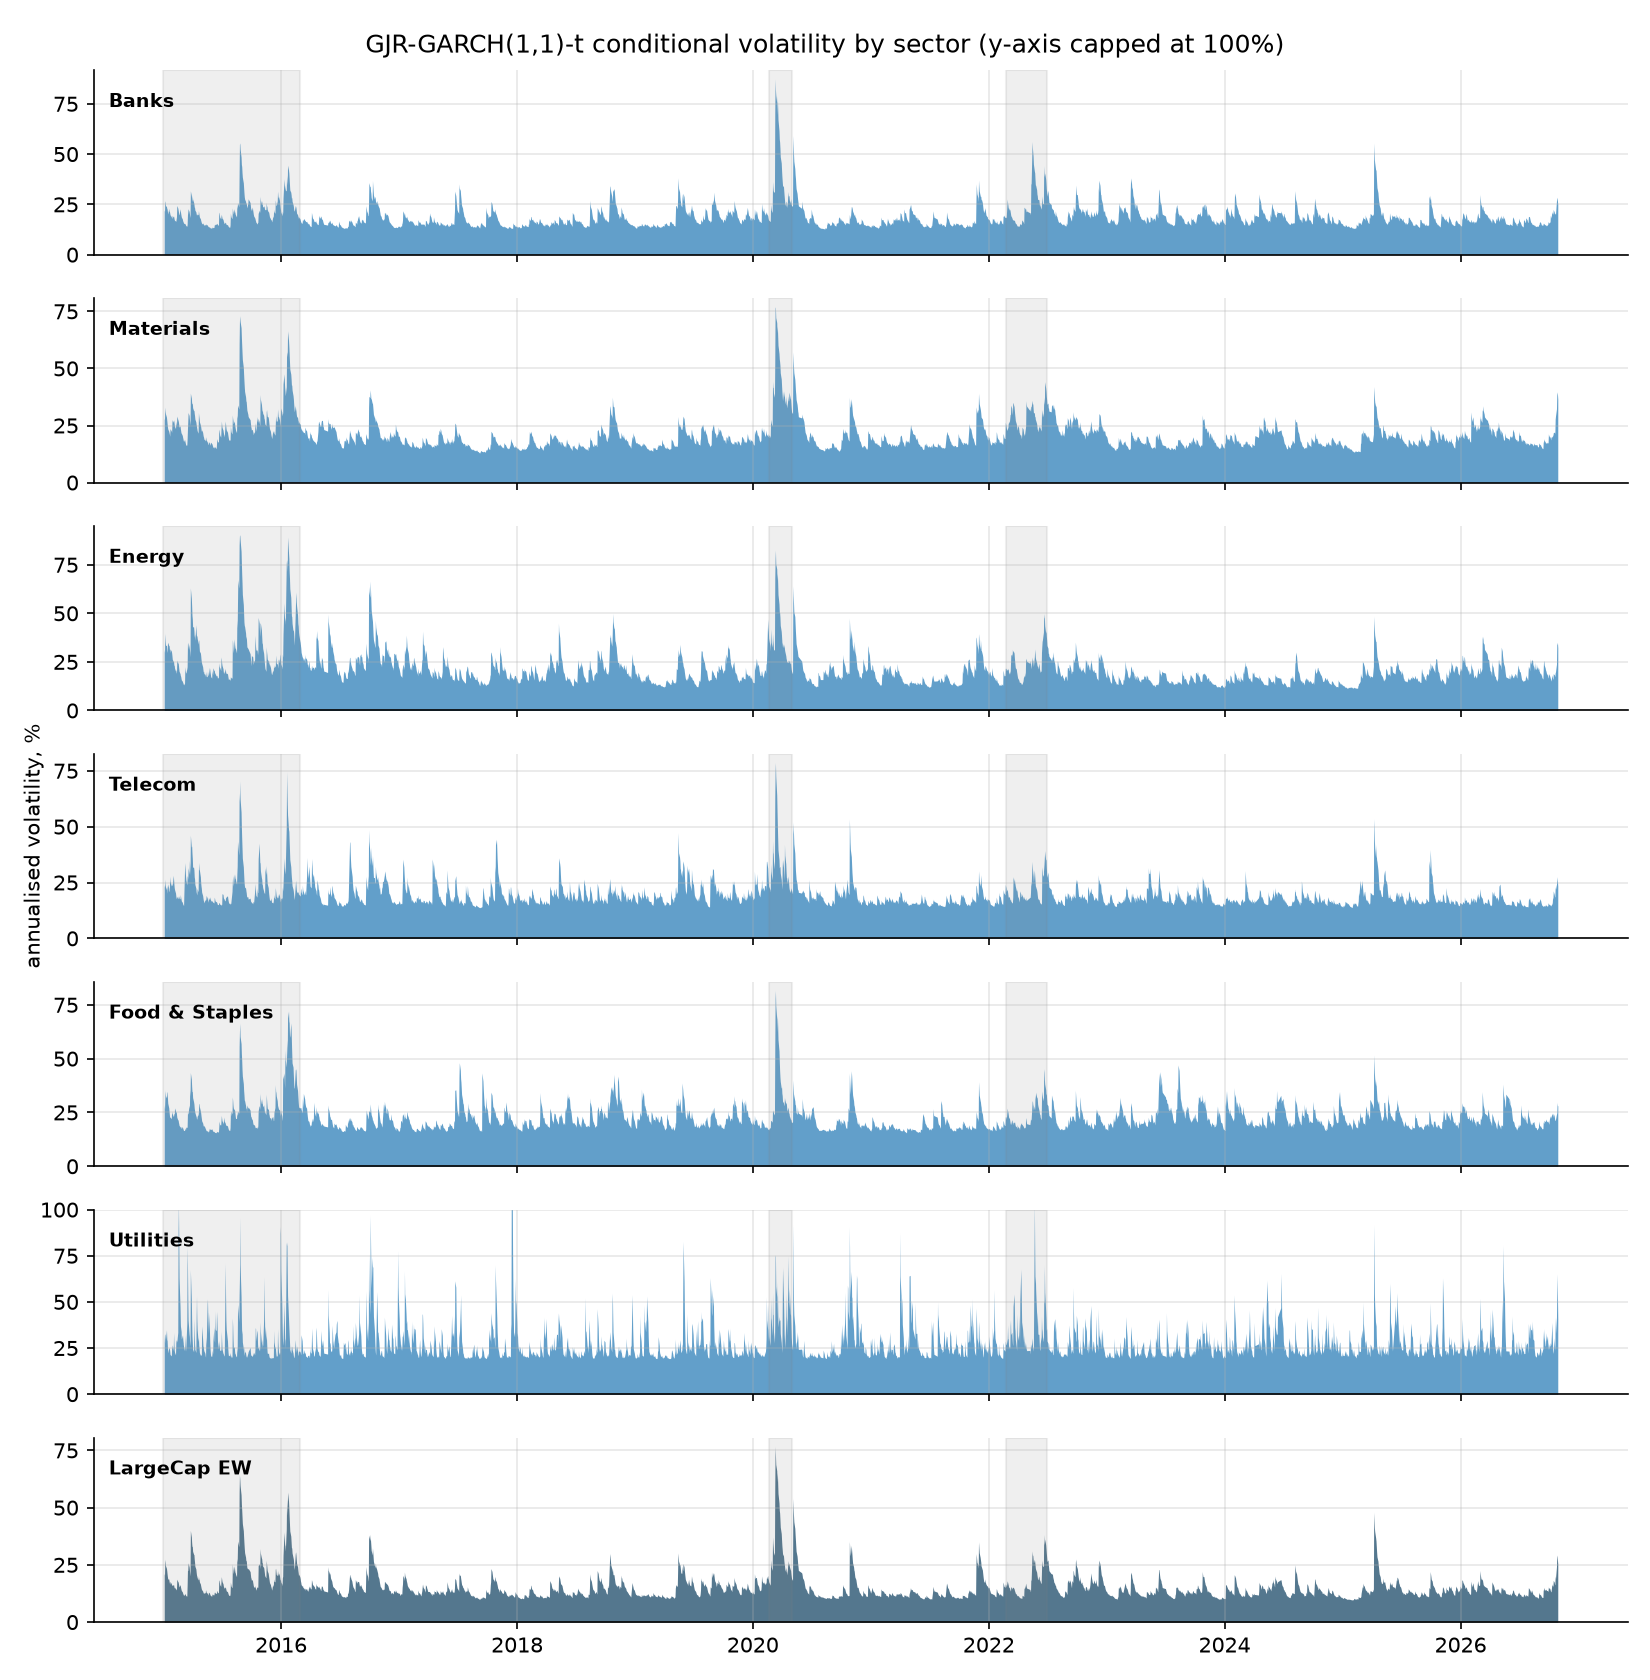

In [4]:
display(Image(str(C.FIG_DIR/'02_gjr_conditional_vol.png')))

## 3. Correlation regimes and Brent

In [5]:
wk = data.weekly(px, daily)
corr.regime_table(daily, wk)[['avg_pairwise_sector_corr','corr_market_brent_weekly','brent_corr_Banks','brent_corr_Energy']]

,avg_pairwise_sector_corr,corr_market_brent_weekly,brent_corr_Banks,brent_corr_Energy
regime,,,,
Oil slump 2015-16,0.618,0.518,0.466,0.534
Recovery 2016-19,0.444,0.222,0.174,0.161
COVID crash 2020,0.768,0.634,0.708,0.546
Post-COVID 2020-21,0.418,0.479,0.398,0.315
Oil spike 2022,0.449,0.436,0.434,0.353
2023-present,0.409,0.190,0.109,0.276


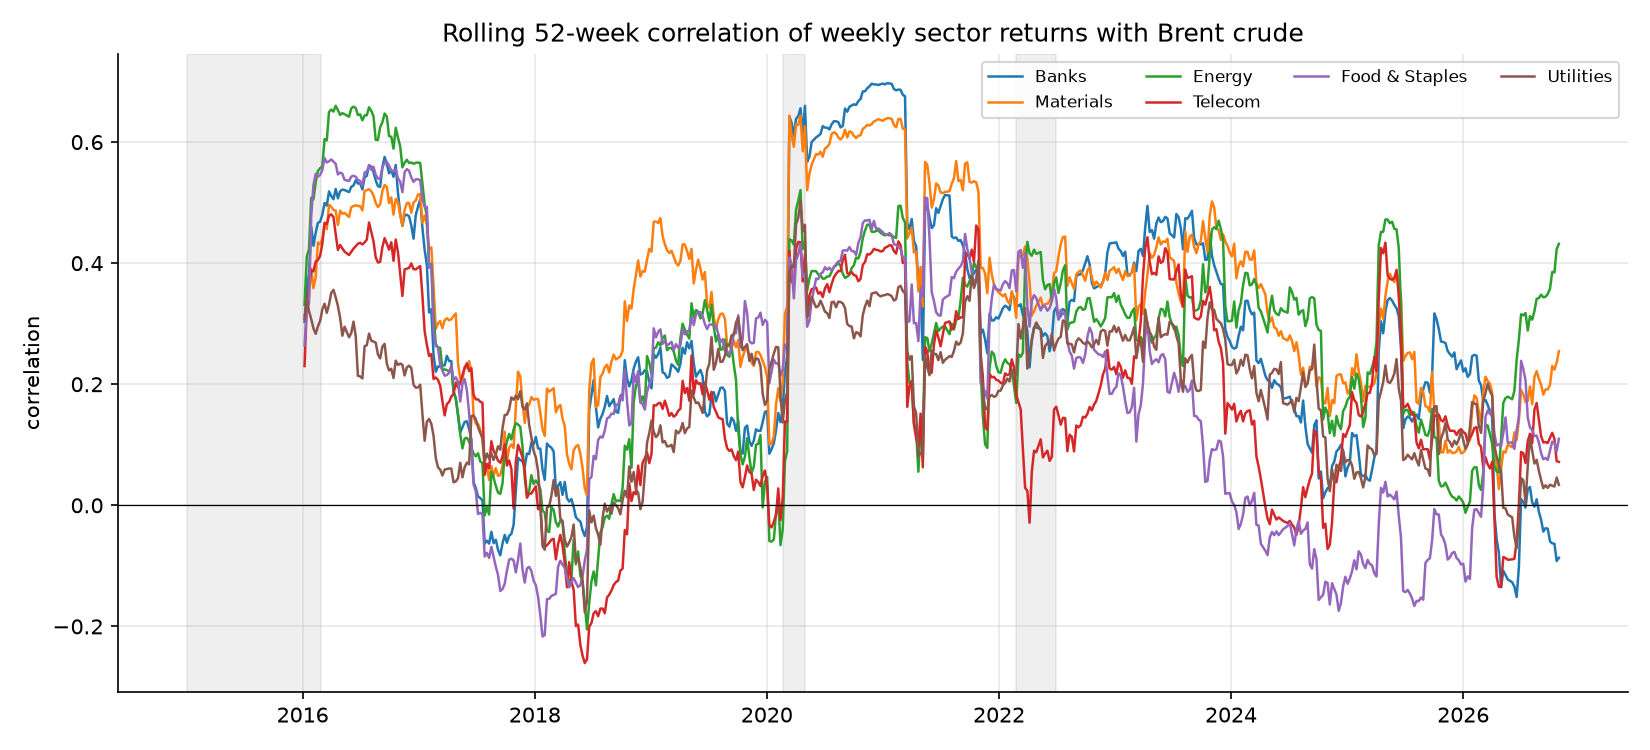

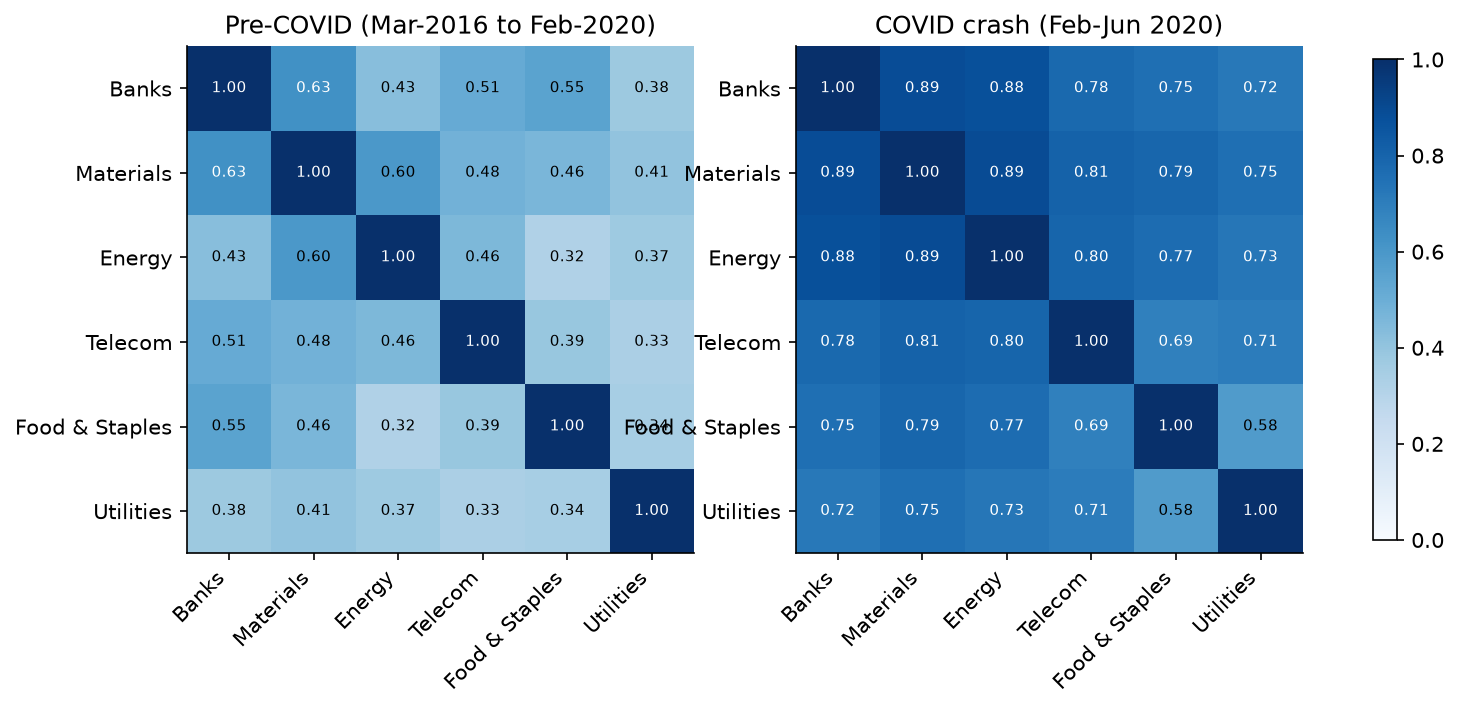

In [6]:
display(Image(str(C.FIG_DIR/'04_rolling_corr_brent.png')))
display(Image(str(C.FIG_DIR/'08_regime_corr_heatmaps.png')))

## 4. Drawdowns

In [7]:
stats.drawdown_table(daily)

,max_drawdown_%,peak,trough,recovered,current_drawdown_%
Banks,-44.111,2019-05-01,2020-03-16,2021-04-28,-14.04
Materials,-47.583,2015-05-04,2016-01-20,2018-01-15,-38.404
Energy,-56.266,2015-05-28,2016-10-18,2020-08-25,-7.371
Telecom,-39.384,2015-03-09,2016-01-17,2019-03-03,-14.549
Food & Staples,-49.451,2015-04-20,2016-01-21,2017-06-18,-29.096
Utilities,-48.555,2024-04-23,2026-03-01,not yet,-43.527
LargeCap EW,-43.719,2015-05-26,2016-01-21,2018-04-08,-10.897


## 5. VaR / ES and Kupiec backtest (composite, 99%)

In [8]:
risk.static_table(daily[[C.MARKET]])

,series,level,method,VaR_%,ES_%
0,LargeCap EW,0.95,Historical,1.549,2.635
1,LargeCap EW,0.95,Normal,1.720,2.164
2,LargeCap EW,0.95,Student-t,1.496,2.404
3,LargeCap EW,0.99,Historical,3.057,4.762
4,LargeCap EW,0.99,Normal,2.445,2.805
5,LargeCap EW,0.99,Student-t,2.829,4.208


In [9]:
fc = risk.rolling_var(daily[C.MARKET], 0.99, C.ROLL_WIN, C.GARCH_WIN, C.GARCH_REFIT)
risk.backtest(fc, 0.99)

,method,level,n,expected,exceedances,rate_%,kupiec_LR,kupiec_p,christoffersen_LR,christoffersen_p,kupiec_verdict
0,Historical,0.99,1978,19.78,30,1.517,4.605,3.188e-02,16.361,5.235e-05,reject
1,Normal,0.99,1978,19.78,42,2.123,19.065,1.263e-05,13.993,1.835e-04,reject
2,GJR-GARCH-t,0.99,1978,19.78,29,1.466,3.796,5.138e-02,3.220,7.272e-02,do not reject


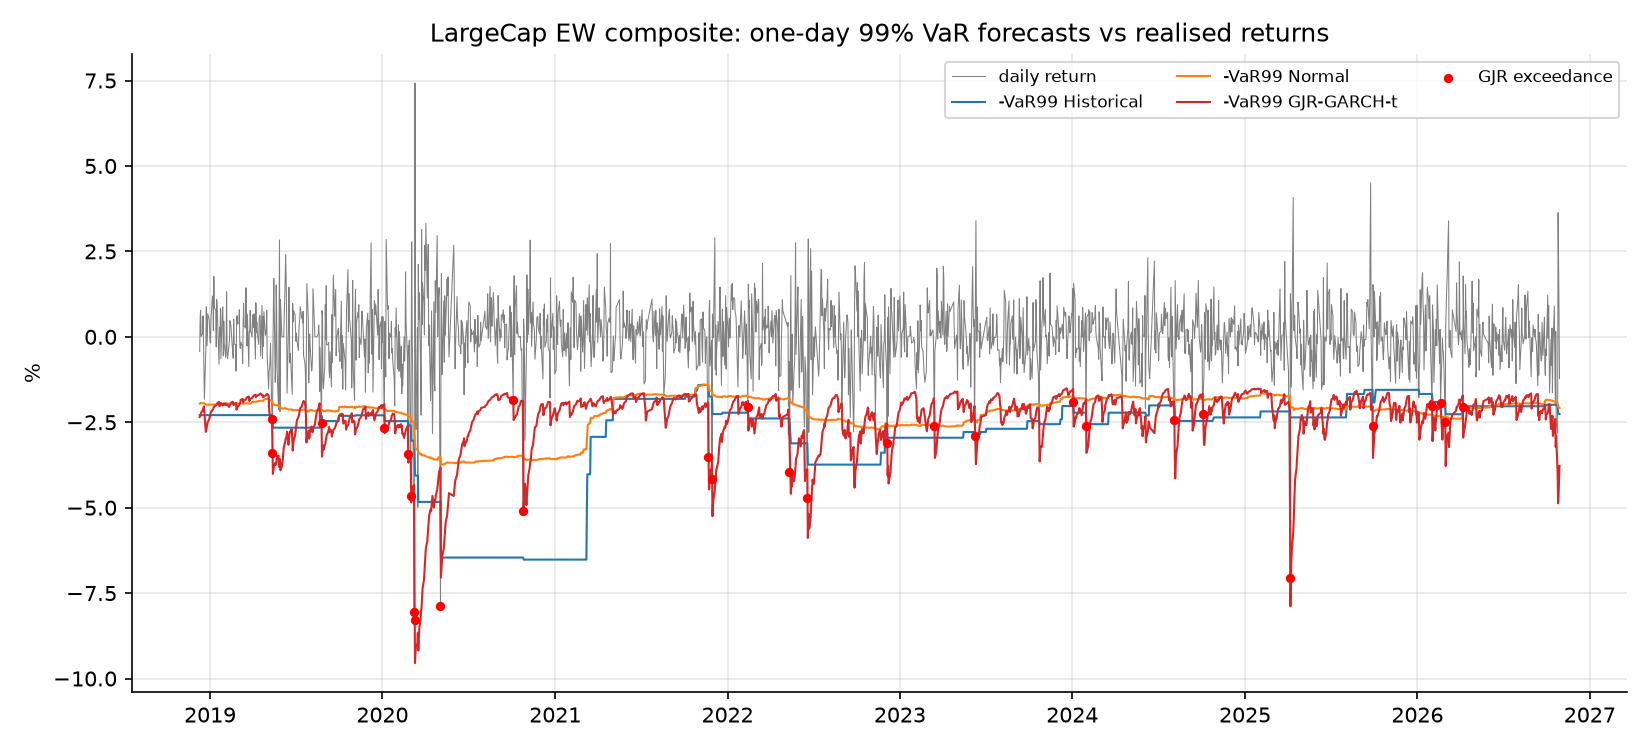

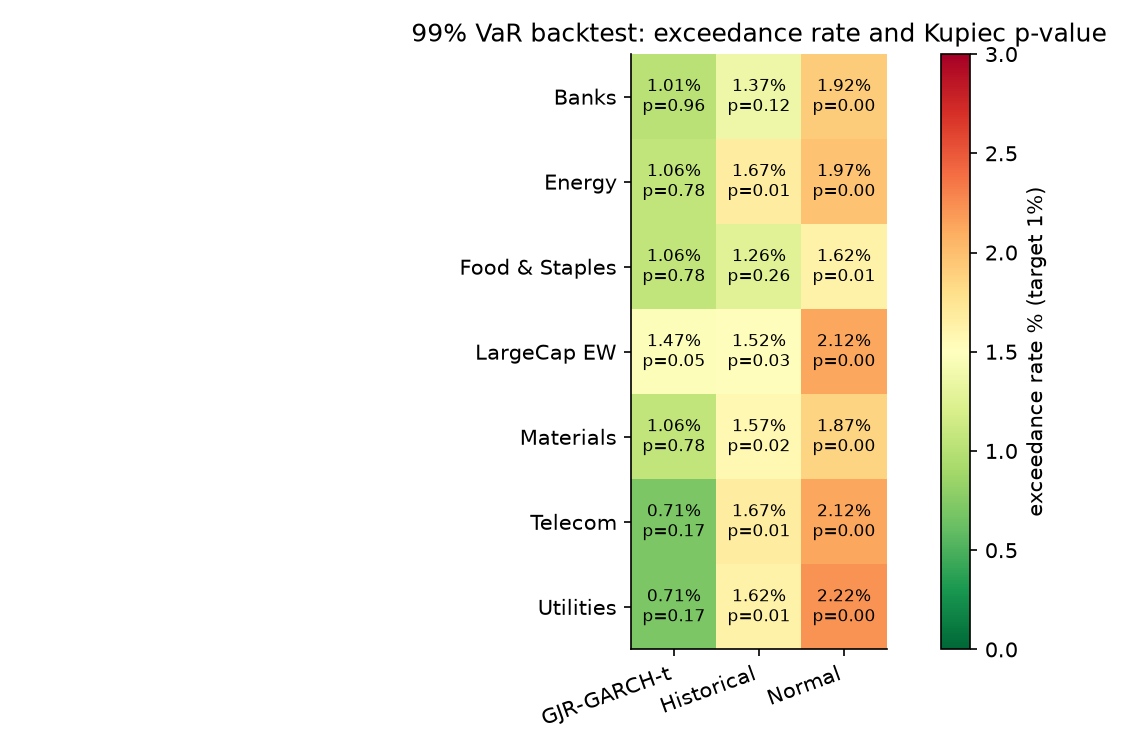

In [10]:
display(Image(str(C.FIG_DIR/'06_var_backtest_market.png')))
display(Image(str(C.FIG_DIR/'07_kupiec_heatmap.png')))

See `reports/tables/` and `reports/figures/` for the full outputs.